# MAE O3 · Online MLP at +16

**Completed online +16 comparison** · updated 2026-11-21T18:46:26+01:00.

Online MAE arrivals **72,000/72,000**. Delayed MLP updates **71,985**.


The 88-input, 48/24-hidden-unit MLP starts with a frozen fit to +16 action advantages from the first 8,000 arrivals. Each forecast scores Skip, 0.25×, and 1× using the O3 utility, −scaled MSE + 0.25 × scaled RankMe. The controller executes the first action. Each forecast assumes 15 subsequent 0.25× updates.

The worker stores the MAE state at forecast time. Once all 16 arrivals have occurred, it evaluates the three matched branches from that state using the observed frames. It scores the issued forecast and then takes one online Adam update. Scalers stay fixed. Final origins with fewer than 16 arrivals remaining use the original +1 Lasso.

The RMSE plots use the last 1,024 available targets for each point. Both nonzero actions are scored, with advantage measured relative to the matched Skip branch. Persistence predicts zero advantage. Frozen and online MLP forecasts are evaluated on the same origins and target draws.


## Matched-stream outcomes
All five trajectories use the same seed, calibration checkpoint and first **72,000** post-calibration arrivals. The frozen controller trajectory is +8. The frozen +16 predictor is evaluated in the forecast RMSE panel.

| Policy | Current MSE ↓ | Bank MSE ↓ | RankMe | Feature variance | O3 utility ↑ |
| --- | ---: | ---: | ---: | ---: | ---: |
| Online +16 MLP | 0.803068 | 0.780127 | 3.36071 | 0.37961 | -1.895380 |
| Online +8 MLP | 0.807271 | 0.786536 | 3.15796 | 0.29216 | -2.106923 |
| Frozen +8 MLP | 0.801613 | 0.779494 | 3.19699 | 0.37648 | -2.036190 |
| Fixed 0.25× | 0.803602 | 0.769109 | 3.24096 | 0.51697 | -2.008267 |
| Fixed 1× | 0.813304 | 0.790749 | 3.23278 | 0.27364 | -2.075809 |

## Realized MAE outcomes
| Policy | Stream MSE | Stream RankMe | O3 utility | Test MSE | Test RankMe |
| --- | ---: | ---: | ---: | ---: | ---: |
| Online MLP | 0.803068 | 3.36071 | -1.895380 | 0.928333 | 3.85762 |
| Online +8 MLP | 0.807271 | 3.15796 | -2.106923 | 0.928815 | 3.14766 |

## Pooled +16 advantage RMSE
| Target | Online MLP | Frozen MLP | Persistence |
| --- | ---: | ---: | ---: |
| Current-image reconstruction MSE | 0.00332859 | 0.00438044 | 0.00384283 |
| Rolling-bank reconstruction MSE | 0.00109267 | 0.00177359 | 0.00103434 |
| RankMe | 0.0178251 | 0.018468 | 0.0179427 |
| Feature variance | 0.00281937 | 0.0029617 | 0.00289562 |

## Downstream probes on the same seed-2026 run

The three endpoints use the same 8,000-arrival calibration and 72,000 post-calibration observations. Scene, weather, day/night, and pedestrian presence reuse the established MAE linear-probe splits. Traffic-light presence uses the archived BDD traffic-light panel with the same linear reader. Scene kNN uses 20 cosine-distance-weighted neighbors on the scene linear split. Labels enter only the probes. Balanced accuracy equally weights classes.

| Policy | Scene linear | Weather | Day / night | Traffic-light presence | Pedestrian presence | Scene kNN |
| --- | --- | --- | --- | --- | --- | --- |
 | Calibration | 44.26% | 43.83% | 96.23% | 58.33% | 58.75% | 39.26% | 
 | Online +16 MLP | 45.19% | 45.68% | 95.26% | 56.23% | 61.88% | 37.96% | 
 | Fixed 0.25× | 45.00% | 46.91% | 96.23% | 56.01% | 58.13% | 40.19% | 
 | Fixed 1× | 44.26% | 46.30% | 98.10% | 56.91% | 56.56% | 37.78% | 

| Probe | vs. 0.25× (pp) | Paired 95% interval | vs. 1× (pp) | Paired 95% interval |
| --- | --- | --- | --- | --- |
 | Scene linear | +0.19 | [-4.08, +4.46] | +0.93 | [-3.80, +5.56] | 
 | Weather | -1.23 | [-6.24, +3.66] | -0.62 | [-6.05, +4.65] | 
 | Day / night | -0.96 | [-3.19, +0.00] | -2.83 | [-7.39, +0.96] | 
 | Traffic-light presence | +0.23 | [-2.77, +3.22] | -0.67 | [-3.26, +1.84] | 
 | Pedestrian presence | +3.75 | [-1.24, +8.79] | +5.31 | [-0.01, +10.81] | 
 | Scene kNN | -2.22 | [-7.01, +2.74] | +0.19 | [-4.93, +5.38] | 

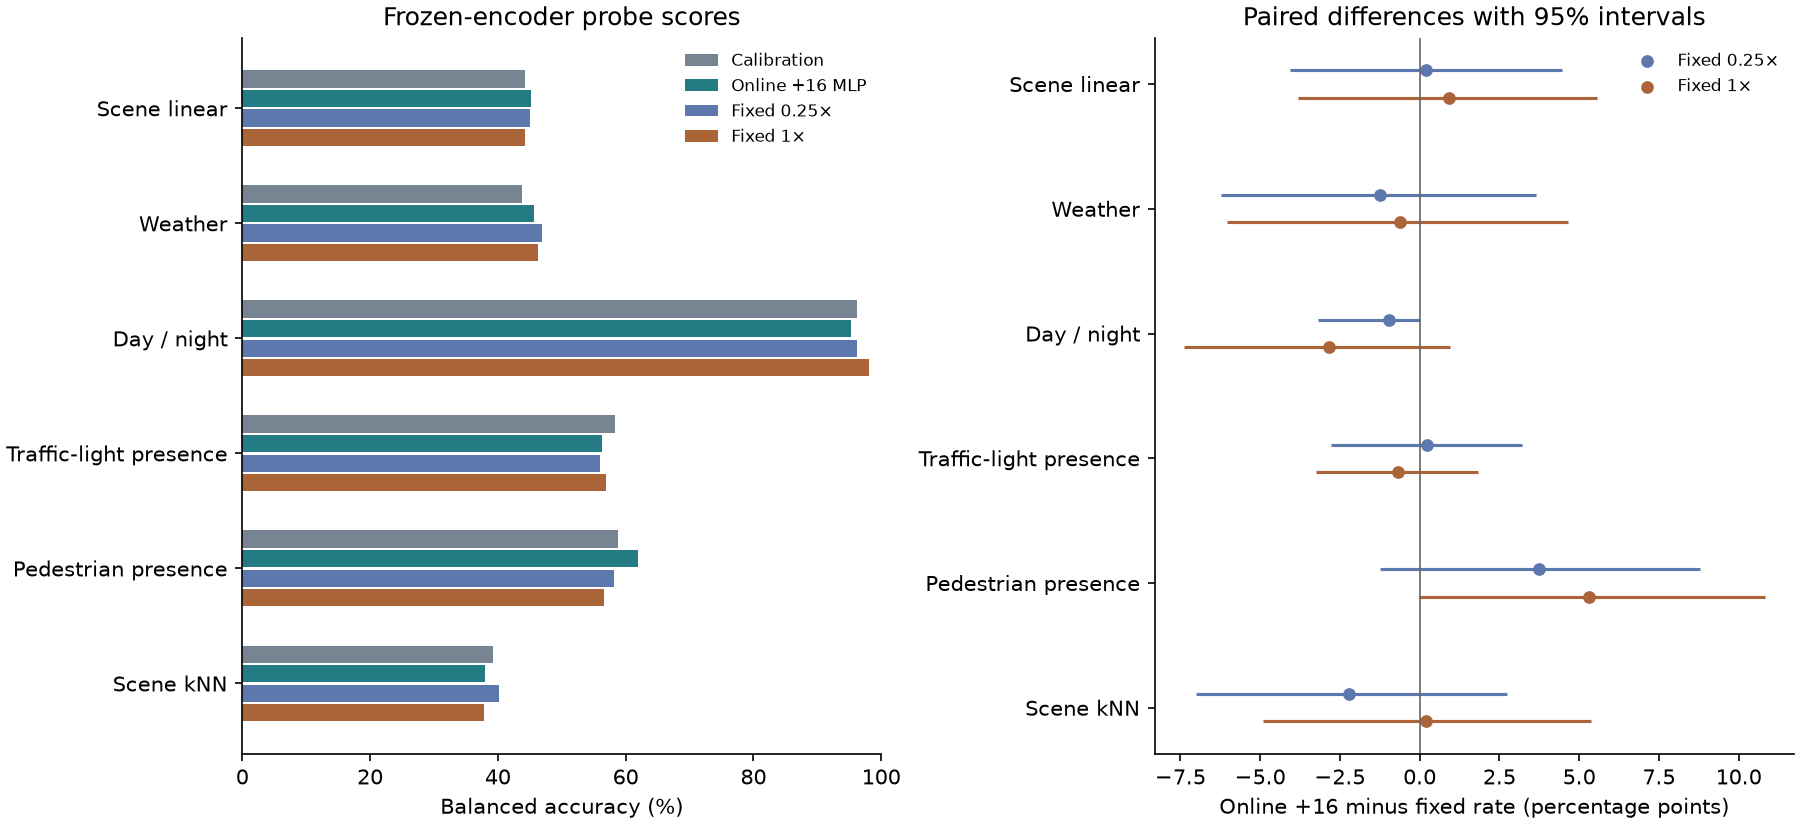

| Probe | Fit images | Test images |
| --- | --- | --- |
 | Scene linear | 1080 | 540 | 
 | Weather | 636 | 324 | 
 | Day / night | 105 | 105 | 
 | Traffic-light presence | 480 | 720 | 
 | Pedestrian presence | 640 | 320 | 
 | Scene kNN | 1080 | 540 | 

The paired intervals resample query capture prefixes with the fitted probes held fixed. The established fit and test splits are disjoint by clip ID and share some capture prefixes. These are endpoint comparisons on one training seed.

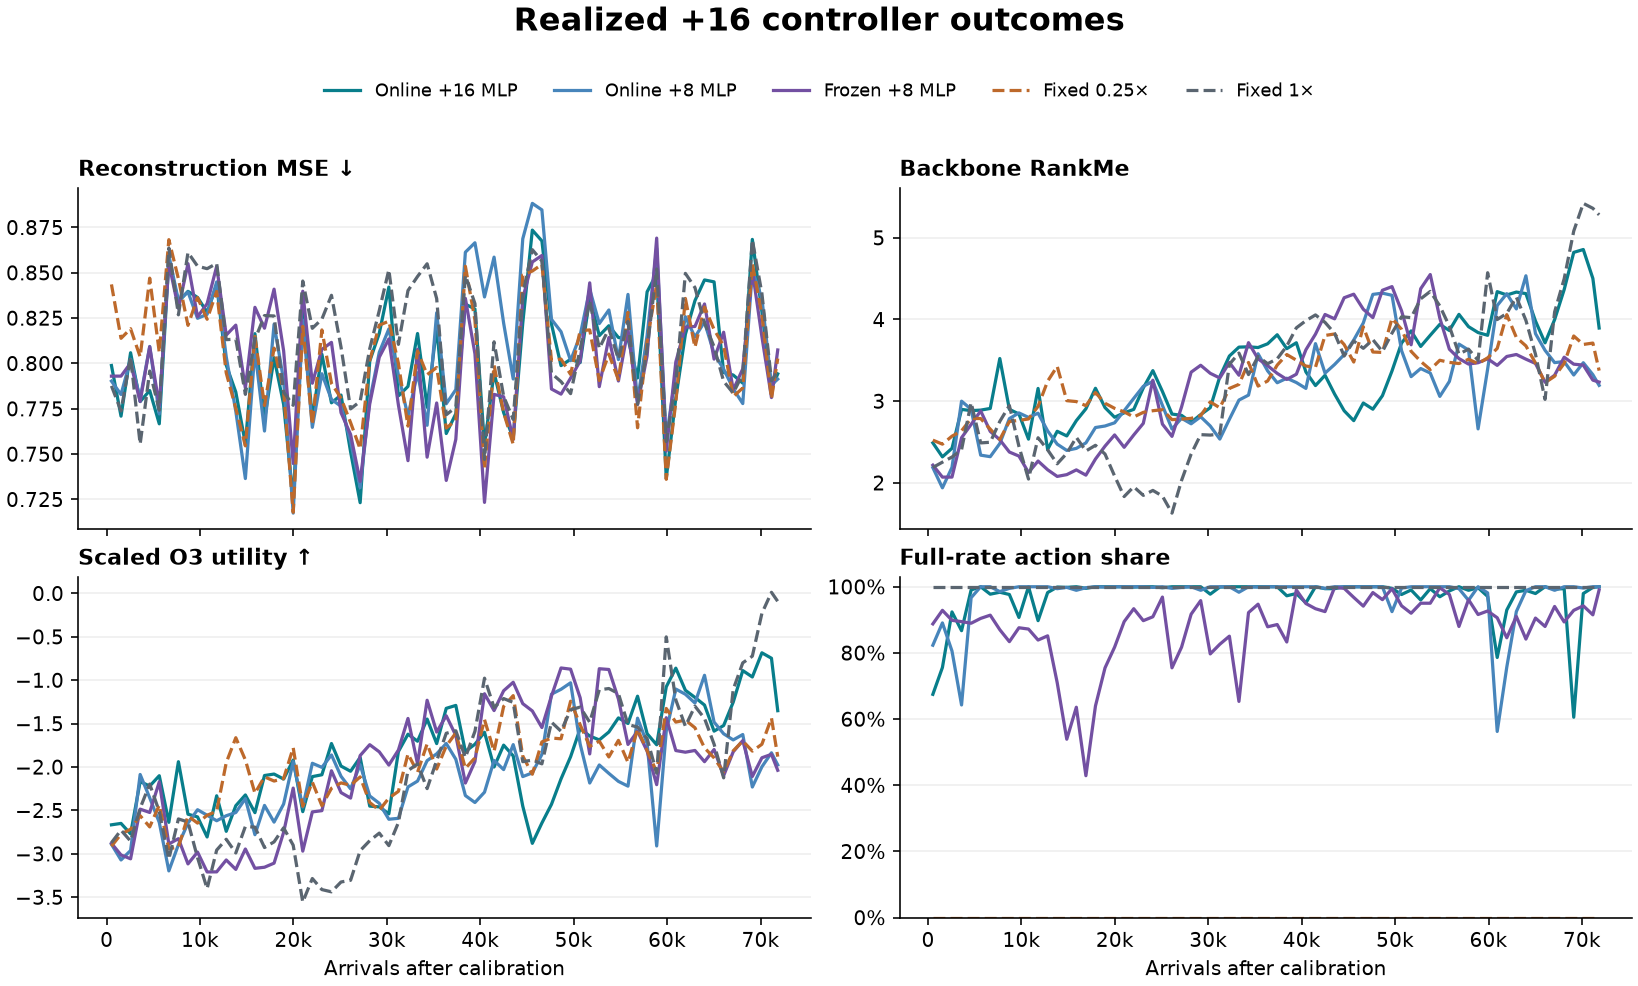

In [ ]:
from pathlib import Path
import sys
from IPython.display import display
import matplotlib.pyplot as plt

folder = Path('C:/CAFL-E/analysis/2026-11-09-one-step-mpc/o3-horizon16-online')
sys.path.insert(0,str(folder.parent.parent if folder.name == "smoke" else folder.parent))
from o3_online8_report import trajectories, read
figure = trajectories(folder, read(folder / "status.json"))
if figure is not None:
    display(figure)
    plt.close(figure)


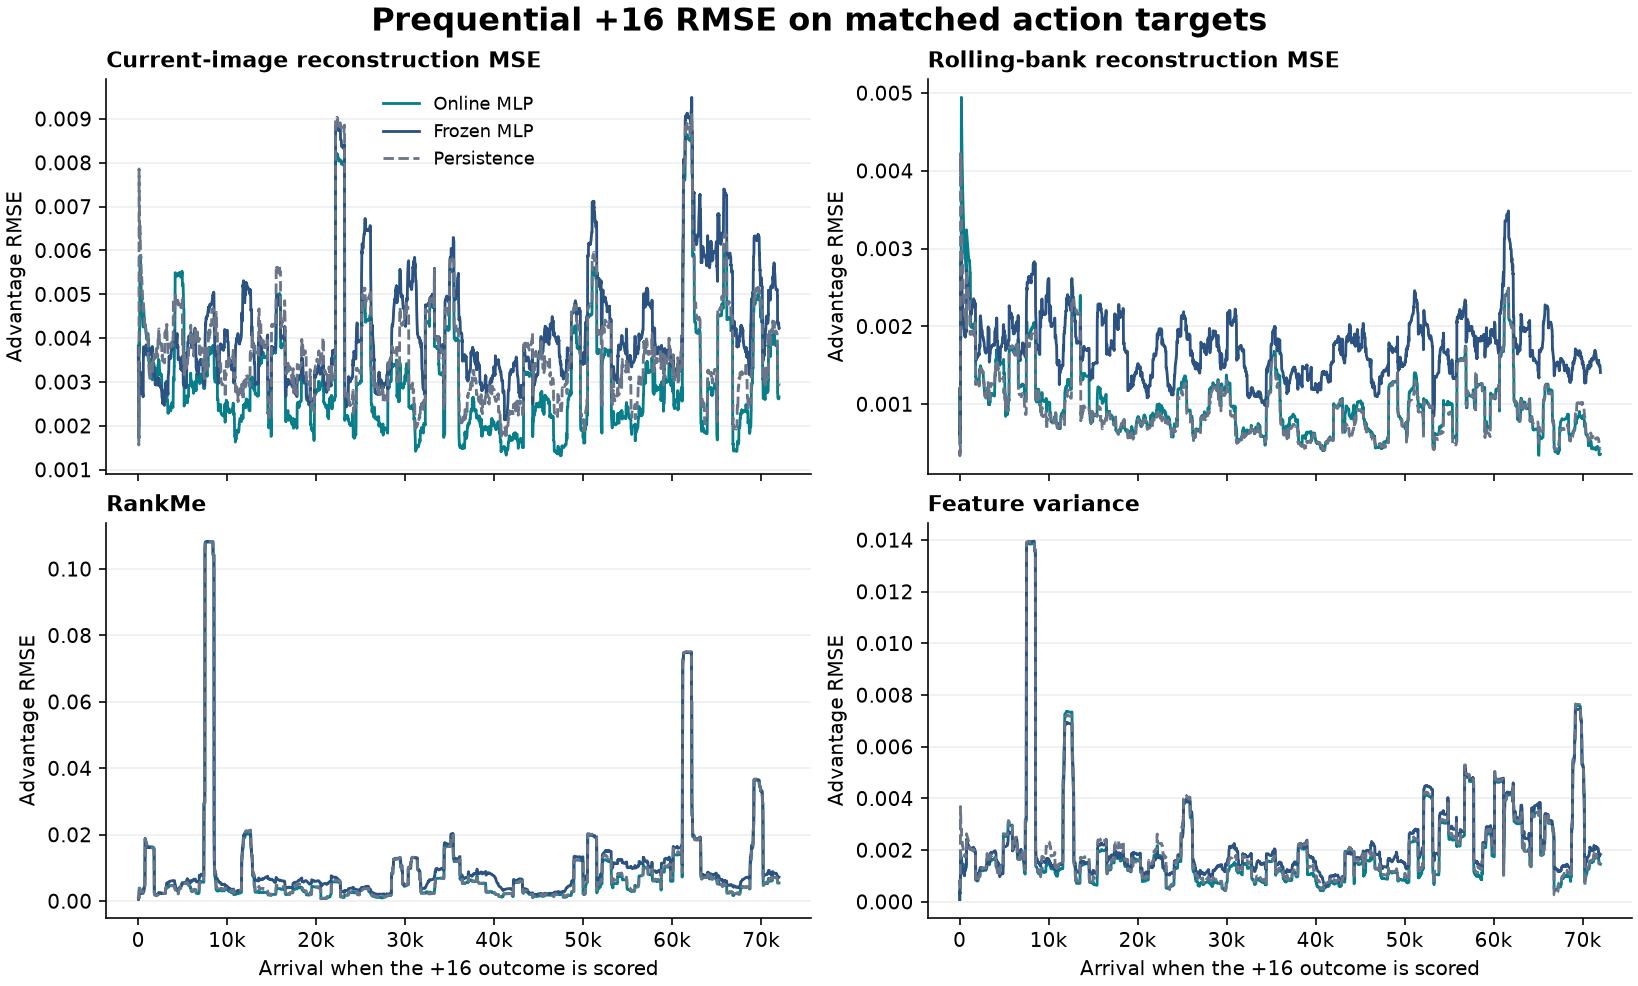

In [ ]:
from pathlib import Path
import sys
from IPython.display import display
import matplotlib.pyplot as plt

folder = Path('C:/CAFL-E/analysis/2026-11-09-one-step-mpc/o3-horizon16-online')
sys.path.insert(0,str(folder.parent.parent if folder.name == "smoke" else folder.parent))
from o3_online8_report import rmse, read
figure = rmse(folder, read(folder / "status.json"))
if figure is not None:
    display(figure)
    plt.close(figure)
